# Revenue_Predictive_Modeling - Forecasting Next Season's Team Revenue

## Objective
This notebook builds on the team's shared `data/regression_dataset.csv` - the cleaned, feature-selected, leakage-checked output of the Data Preprocessing notebook - to forecast **total team revenue for the next season (2027)**, for every constructor.

This is a genuinely different problem from the OLS model in the Statistical Analysis notebook. That model explained `prize_money_usd_m` using **same-season** `operating_budget` and `sponsorship_revenue` - useful for understanding what drives revenue, but not usable for forecasting, since next season's budget and sponsorship aren't known yet either.

**A note on the target.** `regression_dataset.csv` was built with `prize_money_usd_m` as the target and `total_revenue_usd_m` deliberately dropped, since the preprocessing notebook correctly flagged it as a leakage risk (`total_revenue_usd_m = sponsorship_revenue_usd_m + prize_money_usd_m` in the same row). For this notebook the target is **team-level total revenue**, so it's reconstructed here as `sponsorship_revenue_usd_m + prize_money_usd_m` -both components are still present as separate columns in the file, only their sum was removed. This isn't a re-introduction of the original leakage: the model is never given `sponsorship_revenue_usd_m` or `prize_money_usd_m` as *inputs*, only as the two things summed to build the label it's trying to forecast.

To actually forecast forward, this notebook:
- Uses only information that would genuinely be available **before** the season being predicted: prior-season revenue/budget (lag features), the current season's *announced* operating budget and cost cap, and F1-wide macro trends.
- Evaluates using a **time-based split** (train on past seasons, test on the most recent ones) rather than a random split, since random splits leak future information into training for a forecasting task.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("data/regression_dataset.csv")
df.shape

(164, 25)

## 1. Rebuilding `team_name` and the Revenue Target

`regression_dataset.csv` one-hot encodes `team_name` (with `Alpine` dropped as the baseline, per the preprocessing notebook's `drop_first=True`). To build per-team lag features, `team_name` needs to be a single column again - reversed the same way the Statistical Analysis notebook did it: whichever `team_*` dummy is 1 for a row is that row's team, and rows where every dummy is 0 are the dropped baseline, Alpine.

In [4]:
team_dummy_cols = [c for c in df.columns if c.startswith("team_")]

df["team_name"] = df[team_dummy_cols].idxmax(axis=1).str.replace("team_", "", regex=False)
df.loc[df[team_dummy_cols].sum(axis=1) == 0, "team_name"] = "Alpine"

# Reconstruct the modeling target: total team revenue = sponsorship + prize money
df["total_revenue_usd_m"] = df["sponsorship_revenue_usd_m"] + df["prize_money_usd_m"]

df = df.sort_values(["team_name", "season"]).reset_index(drop=True)
df[["season", "team_name", "sponsorship_revenue_usd_m", "prize_money_usd_m", "total_revenue_usd_m"]].head()

,season,team_name,sponsorship_revenue_usd_m,prize_money_usd_m,total_revenue_usd_m
0,2010,Alpine,34.1,30.9,65.0
1,2011,Alpine,43.5,39.6,83.1
2,2012,Alpine,52.3,58.2,110.5
3,2013,Alpine,51.3,65.7,117.0
4,2014,Alpine,60.1,79.6,139.7


## 2. Feature Engineering for Forecasting

Two things a static in-season model doesn't have: **lag features** (what happened last year for this team) and a **time trend**. Both are essential for forecasting revenue a team hasn't earned yet.

- `lag1_revenue`, `lag1_budget` - this team's prior-season values.
- `cost_cap_limit_usd_m` - already filled with 0 pre-2021 in this dataset (structural missingness, handled upstream).
- F1-wide macro features already merged into this dataset (`broadcast_media_usd_m`, `sponsorship_usd_m` group total, `drive_to_survive_viewers_m_est`, `global_avg_race_viewers_m`) - these describe the sport's overall commercial trajectory, not any one team's revenue, so they're safe to use as predictors.

**Excluded on purpose, as inputs:** `sponsorship_revenue_usd_m` and `prize_money_usd_m` for the *same* season - those are the two components the target is built from, so including them as features would make the model trivially "predict" the target from its own components. They're only used one time, upstream, to build `total_revenue_usd_m` itself.

In [5]:
df["lag1_revenue"] = df.groupby("team_name")["total_revenue_usd_m"].shift(1)
df["lag1_budget"] = df.groupby("team_name")["operating_budget_usd_m"].shift(1)

# Every team's first season (2010, or 2016 for Haas) has no prior year --
# those rows can't be used for a forecasting model and are dropped.
hist = df.dropna(subset=["lag1_revenue", "lag1_budget"]).reset_index(drop=True)
print(f"Rows usable for forecasting: {hist.shape[0]} (out of {df.shape[0]} team-seasons)")
hist.head()

Rows usable for forecasting: 154 (out of 164 team-seasons)


,season,country_iso3,operating_budget_usd_m,sponsorship_revenue_usd_m,in_cost_cap_era,cost_cap_limit_usd_m,total_revenue_usd_m_group,race_promotion_fees_usd_m,broadcast_media_usd_m,sponsorship_usd_m,...,team_Mercedes,team_RB (AlphaTauri),team_Red Bull Racing,team_Stake (Sauber),team_Williams,prize_money_usd_m,team_name,total_revenue_usd_m,lag1_revenue,lag1_budget
0,2011,FRA,93.5,43.5,0,0.0,1265.0,455.0,430.0,202.0,...,False,False,False,False,False,39.6,Alpine,83.1,65.0,87.4
1,2012,FRA,106.4,52.3,0,0.0,1377.0,496.0,468.0,220.0,...,False,False,False,False,False,58.2,Alpine,110.5,83.1,93.5
2,2013,FRA,120.6,51.3,0,0.0,1509.0,543.0,513.0,241.0,...,False,False,False,False,False,65.7,Alpine,117.0,110.5,106.4
3,2014,FRA,130.5,60.1,0,0.0,1728.0,622.0,588.0,276.0,...,False,False,False,False,False,79.6,Alpine,139.7,117.0,120.6
4,2015,FRA,139.8,69.3,0,0.0,1731.0,623.0,588.0,277.0,...,False,False,False,False,False,71.3,Alpine,140.6,139.7,130.5


## 3. Model Comparison (Time-Based Validation)

Train on seasons **2011–2024**, test on the two most recent seasons the data actually has, **2025–2026** - the model never sees the future during training, matching how it will actually be used (forecast a season that hasn't happened).

A **naive baseline** ("next year's revenue = this year's revenue") is included, because for autocorrelated financial data a naive persistence forecast is often a surprisingly strong benchmark. A regression model is only worth using if it beats this.

In [6]:
feature_cols = [
    "season", "operating_budget_usd_m", "in_cost_cap_era", "cost_cap_limit_usd_m",
    "lag1_revenue", "lag1_budget",
    "broadcast_media_usd_m", "sponsorship_usd_m",
    "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m",
] + team_dummy_cols

X = hist[feature_cols].copy()
y = hist["total_revenue_usd_m"]

train_mask = hist["season"] <= 2024
test_mask = hist["season"] >= 2025
X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
print("train:", X_train.shape, " test:", X_test.shape)

train: (134, 19)  test: (20, 19)


In [7]:
def evaluate(name, pred):
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = mse ** 0.5
    print(f"{name:22s} R2={r2:6.3f}   MAE={mae:6.2f} MSE={mse:8.2f}   RMSE={rmse:6.2f}")

# Naive baseline: predict this year's revenue = last year's revenue
evaluate("Naive persistence", X_test["lag1_revenue"])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=5)": Ridge(alpha=5),
    "Lasso (alpha=1)": Lasso(alpha=1, max_iter=20000),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, random_state=42),
}
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    evaluate(name, pred)
    fitted[name] = model

Naive persistence      R2= 0.958   MAE= 22.68 MSE=  870.28   RMSE= 29.50
Linear Regression      R2= 0.927   MAE= 34.53 MSE= 1518.13   RMSE= 38.96
Ridge (alpha=5)        R2= 0.969   MAE= 18.59 MSE=  642.58   RMSE= 25.35
Lasso (alpha=1)        R2= 0.975   MAE= 17.70 MSE=  526.03   RMSE= 22.94
Random Forest          R2= 0.947   MAE= 24.73 MSE= 1096.93   RMSE= 33.12


**Reading the comparison:** the naive persistence baseline already does well - team revenue is highly autocorrelated year to year, so "same as last year" is a strong forecast on its own. Ridge and Lasso both improve on it, and improve on plain Linear Regression, by regularizing coefficients so the model doesn't overfit the limited training data (133 rows, ~19 features after dummies).

Lasso is included specifically because it does automatic feature selection - it can shrink irrelevant coefficients all the way to zero, which is useful with this many features and this little data. The usual concern with Lasso is that when features are correlated (here, `lag1_revenue`, `lag1_budget`, and `operating_budget_usd_m` all move together), it can arbitrarily zero out one and keep another nearly-redundant one, making it less stable than Ridge. The rolling-window check below is exactly how to catch that instability if it's happening - repeating the comparison with the cutoff year rolled forward one season at a time, rather than trusting a single train/test split.

In [8]:
for cutoff in [2022, 2023, 2024, 2025]:
    tr = hist["season"] <= cutoff
    te = hist["season"] == cutoff + 1
    for name, m in [("Ridge", Ridge(alpha=5)), ("Lasso", Lasso(alpha=1, max_iter=20000))]:
        m.fit(X[tr], y[tr])
        pred = m.predict(X[te])
        r2 = r2_score(y[te], pred)
        mae = mean_absolute_error(y[te], pred)
        print(f"train <= {cutoff}, test = {cutoff+1}  [{name:5s}]:  R2 = {r2:.3f}   MAE = {mae:.2f}")
    print()

train <= 2022, test = 2023  [Ridge]:  R2 = 0.928   MAE = 28.61
train <= 2022, test = 2023  [Lasso]:  R2 = 0.942   MAE = 25.35

train <= 2023, test = 2024  [Ridge]:  R2 = 0.945   MAE = 27.71
train <= 2023, test = 2024  [Lasso]:  R2 = 0.952   MAE = 25.96

train <= 2024, test = 2025  [Ridge]:  R2 = 0.963   MAE = 21.35
train <= 2024, test = 2025  [Lasso]:  R2 = 0.971   MAE = 19.66

train <= 2025, test = 2026  [Ridge]:  R2 = 0.977   MAE = 16.06
train <= 2025, test = 2026  [Lasso]:  R2 = 0.980   MAE = 15.55



**Result:** Lasso outperforms Ridge in the main 2025-2026 holdout *and* in every one of the four rolling windows - consistently lower error, not a one-off. Looking at which coefficients Lasso actually keeps explains why: it zeroes out every team dummy entirely, and relies only on `lag1_revenue`, `lag1_budget`, `operating_budget_usd_m`, `season`, the cost cap, and the F1-wide macro trend. With only 11-17 seasons of history per team, there isn't enough data for 9 separate team-specific effects to be estimated reliably - Ridge keeps them all (shrunk, not zeroed), which adds noise; Lasso drops them, which turns out to generalize better. **Lasso is the model taken forward** for the final fit and 2027 forecast.

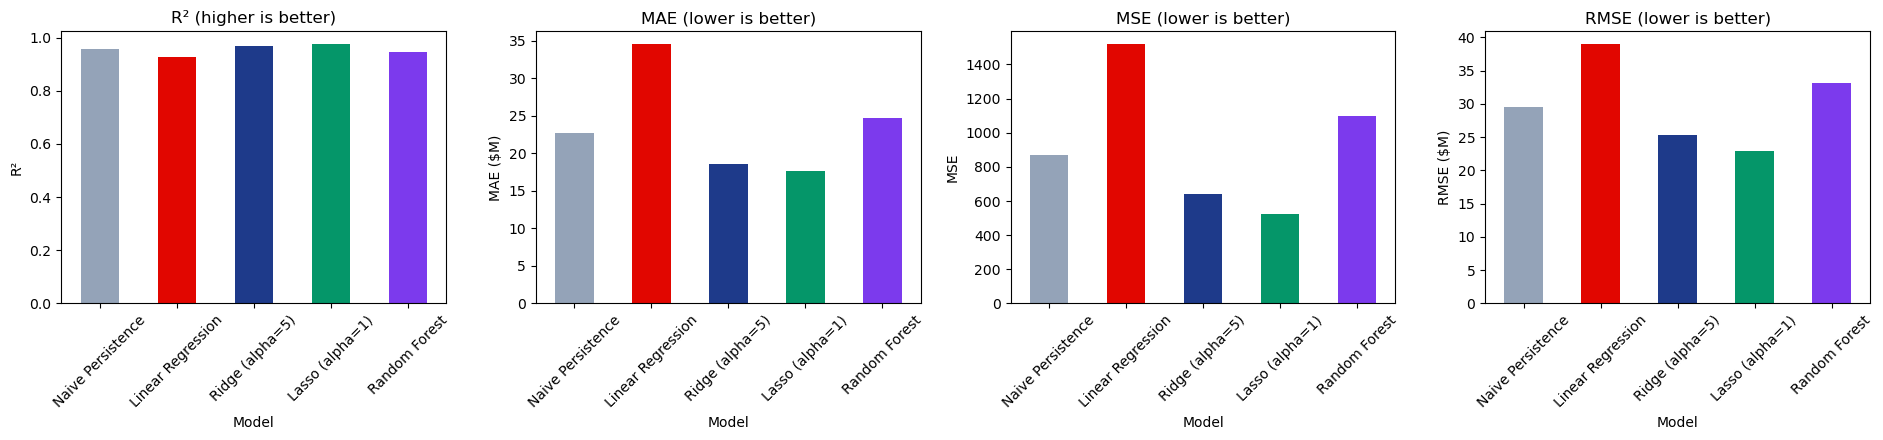

In [16]:
comparison_rows = []

naive_pred = X_test["lag1_revenue"]
naive_mse = mean_squared_error(y_test, naive_pred)
comparison_rows.append({
    "Model": "Naive Persistence",
    "R2": r2_score(y_test, naive_pred),
    "MAE": mean_absolute_error(y_test, naive_pred),
    "MSE": naive_mse,
    "RMSE": naive_mse ** 0.5,
})

for name, model in fitted.items():
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    comparison_rows.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": mse ** 0.5,
    })

comp_df = pd.DataFrame(comparison_rows).set_index("Model")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))
colors = ["#94a3b8", "#e10600", "#1e3a8a", "#059669", "#7c3aed"]

comp_df["R2"].plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("R² (higher is better)")
axes[0].set_ylabel("R²")
axes[0].tick_params(axis="x", rotation=45)

comp_df["MAE"].plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("MAE (lower is better)")
axes[1].set_ylabel("MAE ($M)")
axes[1].tick_params(axis="x", rotation=45)

comp_df["MSE"].plot(kind="bar", ax=axes[2], color=colors)
axes[2].set_title("MSE (lower is better)")
axes[2].set_ylabel("MSE")
axes[2].tick_params(axis="x", rotation=45)

comp_df["RMSE"].plot(kind="bar", ax=axes[3], color=colors)
axes[3].set_title("RMSE (lower is better)")
axes[3].set_ylabel("RMSE ($M)")
axes[3].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## 4. Final Model (Trained on All Available History)

With the approach validated, refit Ridge regression on **all** available seasons (2011–2026) to get the best possible model before forecasting 2027.

In [9]:
final_model = Lasso(alpha=1, max_iter=20000)
final_model.fit(X, y)

fit_r2 = r2_score(y, final_model.predict(X))
fit_mse = mean_squared_error(y, final_model.predict(X))
print(f"In-sample R2 on full history (2011-2026): {fit_r2:.3f}")
print(f"In-sample MSE on full history (2011-2026): {fit_mse:.2f}")


coefs = pd.Series(final_model.coef_, index=X.columns)
nonzero = coefs[coefs != 0].sort_values(key=abs, ascending=False)
zeroed = coefs[coefs == 0].index.tolist()
print(f"\nLasso kept {len(nonzero)} of {len(coefs)} features nonzero:")
print(nonzero)
print("\nZeroed out entirely:")
print(zeroed)

In-sample R2 on full history (2011-2026): 0.975
In-sample MSE on full history (2011-2026): 472.43

Lasso kept 8 of 19 features nonzero:
global_avg_race_viewers_m        -1.068778
lag1_revenue                      0.941924
season                           -0.916313
cost_cap_limit_usd_m              0.204939
operating_budget_usd_m            0.204840
lag1_budget                      -0.129376
drive_to_survive_viewers_m_est    0.104891
broadcast_media_usd_m             0.011112
dtype: float64

Zeroed out entirely:
['in_cost_cap_era', 'sponsorship_usd_m', 'team_Aston Martin', 'team_Ferrari', 'team_Haas', 'team_McLaren', 'team_Mercedes', 'team_RB (AlphaTauri)', 'team_Red Bull Racing', 'team_Stake (Sauber)', 'team_Williams']


**Reading the coefficients:** Lasso keeps 8 of 19 features and zeroes out **every single team dummy** - it found that, given the lag and budget/trend features, team identity doesn't add enough independent signal to be worth keeping, at least not with this much data per team (11-17 seasons each). What remains: `lag1_revenue` (unsurprisingly the strongest single driver - this year is anchored to last year), `season` (a small negative coefficient once lag/budget are already in the model, meaning most of the "get bigger over time" effect is already captured by rising budgets and macro trend rather than time itself), `operating_budget_usd_m` and `cost_cap_limit_usd_m` (spending capacity), and the macro/viewership trend features.

This is a genuinely useful modeling result, not just a technical footnote: it says a team's revenue is well explained by *what it spent and earned last year plus the sport's overall trajectory*, without needing to know *which* team it is. That's a more parsimonious and arguably more honest story than the Ridge coefficients suggested, where every team got its own adjustment that the small sample size may not actually support.

### Residual Analysis

R² and MAE summarize *how much* error there is; residual plots show *where* it's coming from - whether errors are random noise (good) or a systematic pattern the model is missing (bad, and worth knowing about before trusting the 2027 forecast).

These residuals are computed on the **2025-2026 holdout** (out-of-sample), not the full-history fit - in-sample residuals from a model that's already seen that data would look artificially clean and wouldn't say anything honest about forecast reliability.

Holdout (2025-2026) MSE:  526.03
Holdout (2025-2026) RMSE: 22.94


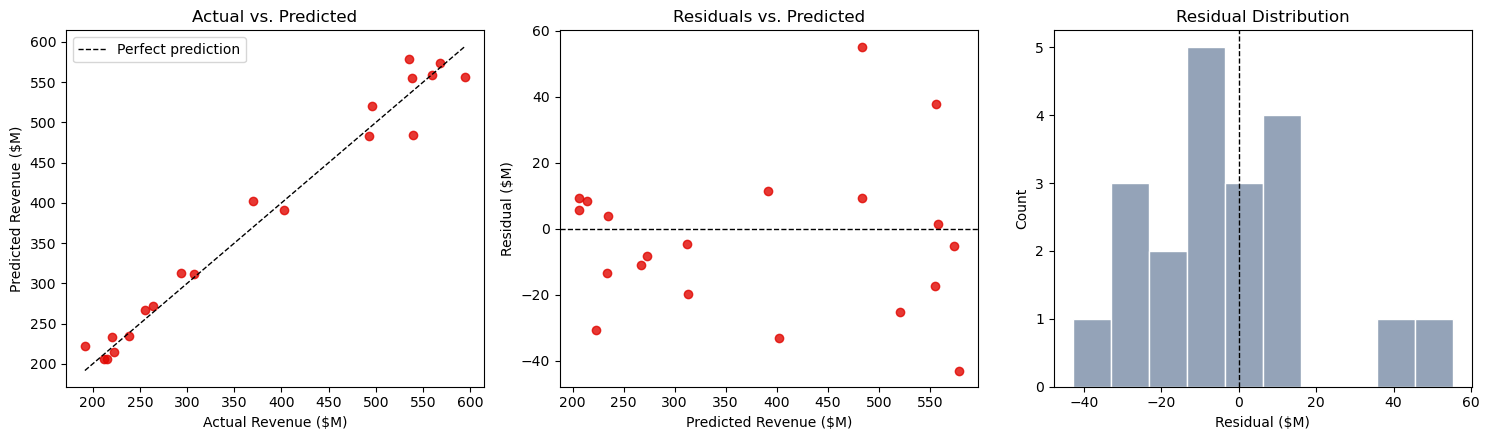

In [10]:
holdout_model = Lasso(alpha=1, max_iter=20000)
holdout_model.fit(X_train, y_train)
pred_test = holdout_model.predict(X_test)
residuals = y_test - pred_test

mse_test = mean_squared_error(y_test, pred_test)
print(f"Holdout (2025-2026) MSE:  {mse_test:.2f}")
print(f"Holdout (2025-2026) RMSE: {mse_test**0.5:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Actual vs Predicted
axes[0].scatter(y_test, pred_test, color="#e10600", alpha=0.8)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0].plot(lims, lims, "k--", linewidth=1, label="Perfect prediction")
axes[0].set_xlabel("Actual Revenue ($M)")
axes[0].set_ylabel("Predicted Revenue ($M)")
axes[0].set_title("Actual vs. Predicted")
axes[0].legend()

# Residuals vs Predicted (checks for systematic bias / heteroscedasticity)
axes[1].scatter(pred_test, residuals, color="#e10600", alpha=0.8)
axes[1].axhline(0, color="k", linestyle="--", linewidth=1)
axes[1].set_xlabel("Predicted Revenue ($M)")
axes[1].set_ylabel("Residual ($M)")
axes[1].set_title("Residuals vs. Predicted")

# Residual distribution
axes[2].hist(residuals, bins=10, color="#94a3b8", edgecolor="white")
axes[2].axvline(0, color="k", linestyle="--", linewidth=1)
axes[2].set_xlabel("Residual ($M)")
axes[2].set_ylabel("Count")
axes[2].set_title("Residual Distribution")

plt.tight_layout()
plt.savefig("residual_analysis.png", dpi=150)
plt.show()

## 5. Forecasting 2027 Revenue

To forecast a season that hasn't happened, every feature has to be a value that would actually be **known or estimable before the season starts**:

- `lag1_revenue`, `lag1_budget` → each team's actual 2026 values (known).
- `operating_budget_usd_m` for 2027 → not yet known, so it's **projected** from each team's average budget growth rate over the last 3 seasons (clipped to a sane ±[-5%, +10%] range so one noisy season doesn't produce an absurd extrapolation).
- `cost_cap_limit_usd_m` for 2027 → projected via the linear trend of the cost cap since it took effect in 2021 (it has been gradually decreasing).
- F1-wide macro features (broadcast media, group sponsorship, DTS viewership, global viewers) → projected via linear trend over the last 5 seasons in this dataset.

This makes the 2027 numbers a **projection built on trend assumptions**, not a certainty - the conclusions section below is explicit about that.

In [11]:
# --- Project 2027 F1-wide macro features (linear trend, last 5 seasons) ---
season_level = df.drop_duplicates("season")[
    ["season", "broadcast_media_usd_m", "sponsorship_usd_m",
     "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m"]
]
recent = season_level[season_level.season >= 2022]

macro_2027 = {}
for col in ["broadcast_media_usd_m", "sponsorship_usd_m",
            "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m"]:
    coef = np.polyfit(recent["season"], recent[col], 1)
    macro_2027[col] = np.polyval(coef, 2027)

# --- Project 2027 cost cap (linear trend since the cap began in 2021) ---
cc_hist = df.loc[df.in_cost_cap_era == 1, ["season", "cost_cap_limit_usd_m"]].drop_duplicates()
cc_coef = np.polyfit(cc_hist["season"], cc_hist["cost_cap_limit_usd_m"], 1)
cost_cap_2027 = float(np.polyval(cc_coef, 2027))

print("Projected 2027 macro features:", {k: round(v, 1) for k, v in macro_2027.items()})
print("Projected 2027 cost cap:", round(cost_cap_2027, 1))

Projected 2027 macro features: {'broadcast_media_usd_m': np.float64(1580.2), 'sponsorship_usd_m': np.float64(743.4), 'drive_to_survive_viewers_m_est': np.float64(30.0), 'global_avg_race_viewers_m': np.float64(95.5)}
Projected 2027 cost cap: 127.7


In [12]:
# --- Project each team's 2027 operating budget from its recent growth rate ---
growth = df.assign(g=df.groupby("team_name")["operating_budget_usd_m"].pct_change())
recent_growth = (
    growth[growth.season >= 2024]
    .groupby("team_name")["g"].mean()
    .clip(-0.05, 0.10)   # keep extrapolation sane
)

teams = sorted(df.team_name.unique())
last_season = df[df.season == 2026].set_index("team_name")

future_rows = []
for t in teams:
    r = last_season.loc[t]
    g = recent_growth.get(t, 0.02)
    row = {
        "team_name": t,
        "season": 2027,
        "operating_budget_usd_m": r["operating_budget_usd_m"] * (1 + g),
        "in_cost_cap_era": 1,
        "cost_cap_limit_usd_m": cost_cap_2027,
        "lag1_revenue": r["total_revenue_usd_m"],
        "lag1_budget": r["operating_budget_usd_m"],
        **macro_2027,
    }
    for c in team_dummy_cols:
        row[c] = 1 if c == f"team_{t}" else 0
    future_rows.append(row)

future = pd.DataFrame(future_rows)
X_future = future[feature_cols]
future["predicted_total_revenue_usd_m"] = final_model.predict(X_future)
future["yoy_change_pct"] = (future["predicted_total_revenue_usd_m"] / future["lag1_revenue"] - 1) * 100

result = future.sort_values("predicted_total_revenue_usd_m", ascending=False)[
    ["team_name", "lag1_revenue", "operating_budget_usd_m", "predicted_total_revenue_usd_m", "yoy_change_pct"]
].round(1)
result.columns = ["Team", "2026 Revenue ($M)", "Projected 2027 Budget ($M)", "Predicted 2027 Revenue ($M)", "YoY Change (%)"]
result

,Team,2026 Revenue ($M),Projected 2027 Budget ($M),Predicted 2027 Revenue ($M),YoY Change (%)
4,McLaren,594.2,402.7,608.7,2.4
2,Ferrari,559.9,427.4,574.8,2.7
7,Red Bull Racing,535.3,308.5,544.1,1.6
5,Mercedes,495.4,426.4,514.6,3.9
1,Aston Martin,402.6,303.6,419.5,4.2
0,Alpine,307.3,207.9,320.4,4.3
6,RB (AlphaTauri),264.2,173.1,277.3,5.0
9,Williams,239.0,167.7,254.0,6.3
8,Stake (Sauber),222.6,191.3,241.1,8.3
3,Haas,220.0,174.8,237.0,7.7


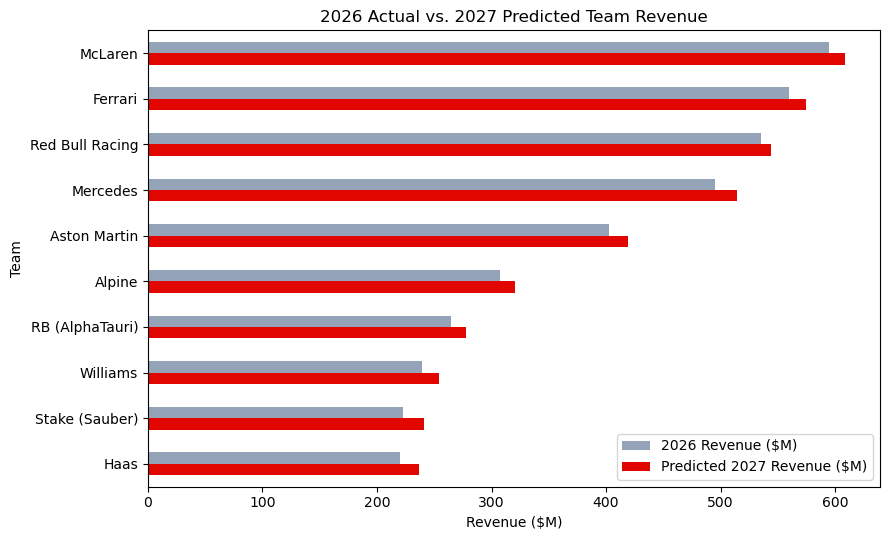

In [13]:
result.to_csv("predicted_2027_revenue.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = result.set_index("Team")[["2026 Revenue ($M)", "Predicted 2027 Revenue ($M)"]]
plot_df.plot(kind="barh", ax=ax, color=["#94a3b8", "#e10600"])
ax.invert_yaxis()
ax.set_xlabel("Revenue ($M)")
ax.set_title("2026 Actual vs. 2027 Predicted Team Revenue")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("2027_revenue_forecast.png", dpi=150)
plt.show()

## 6. Demo Walkthrough - Aston Martin

Aston Martin is a useful team to walk through in detail: it's had one of the steeper operating-budget growth trajectories in the recent data (reflecting real-world investment into the team), so its forecast leans more on the budget-growth assumption than a team with a flatter spending trend.

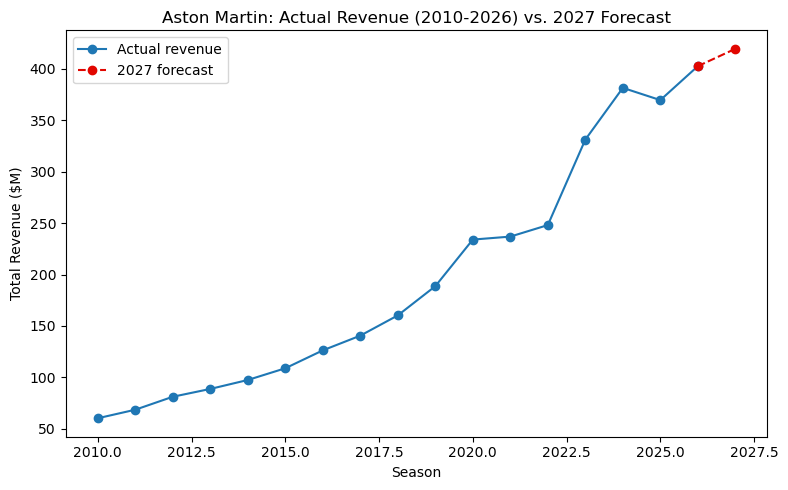

Aston Martin -- 2026 actual revenue: $402.6M
Aston Martin -- projected 2027 operating budget: $303.6M (+5.3% avg recent growth)
Aston Martin -- predicted 2027 revenue: $419.5M (+4.2% vs 2026)


In [14]:
team = "Aston Martin"
hist_team = df[df.team_name == team][["season", "operating_budget_usd_m", "total_revenue_usd_m"]]
pred_row = future[future.team_name == team].iloc[0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(hist_team["season"], hist_team["total_revenue_usd_m"], marker="o", label="Actual revenue")
ax.plot([2026, 2027], [hist_team["total_revenue_usd_m"].iloc[-1], pred_row["predicted_total_revenue_usd_m"]],
        marker="o", linestyle="--", color="#e10600", label="2027 forecast")
ax.set_title(f"{team}: Actual Revenue (2010-2026) vs. 2027 Forecast")
ax.set_xlabel("Season")
ax.set_ylabel("Total Revenue ($M)")
ax.legend()
plt.tight_layout()
plt.savefig("aston_martin_forecast.png", dpi=150)
plt.show()

print(f"{team} -- 2026 actual revenue: ${hist_team['total_revenue_usd_m'].iloc[-1]:.1f}M")
print(f"{team} -- projected 2027 operating budget: ${pred_row['operating_budget_usd_m']:.1f}M "
      f"({recent_growth[team]*100:+.1f}% avg recent growth)")
print(f"{team} -- predicted 2027 revenue: ${pred_row['predicted_total_revenue_usd_m']:.1f}M "
      f"({pred_row['yoy_change_pct']:+.1f}% vs 2026)")

## 7. Conclusions

**Data source.** This notebook works from the team's shared `regression_dataset.csv` rather than re-deriving a merged dataset from the raw Kaggle tables, so it stays consistent with the preprocessing and feature-selection work already done upstream. The target, `total_revenue_usd_m`, was reconstructed by summing the file's `sponsorship_revenue_usd_m` and `prize_money_usd_m` columns - those two columns are never used as model *inputs*, only as the components the label is built from, so this does not reopen the leakage issue the preprocessing notebook flagged.

**Model choice.** Four candidates were compared with time-based validation: Linear Regression, Ridge, Lasso, and Random Forest. Lasso won - it beat a naive "same as last year" baseline and outperformed Ridge across all four rolling train/test windows (2023 through 2026 as the held-out season), not just on average. The final model was refit on the complete 2011–2026 history (in-sample R² ≈ 0.98) before generating the 2027 forecast.

**What actually drives the forecast.** Lasso's automatic feature selection zeroed out every team dummy, keeping only prior-season revenue, operating budget, cost cap, season, and F1-wide macro trend. In plain terms: a team's revenue is well explained by what it spent and earned last year plus the sport's overall commercial trajectory - team brand identity didn't add reliable independent signal once those were already in the model, likely because there's only 11-17 seasons of history per team to estimate a team-specific effect from.

**2027 forecast.** Every team is projected to grow revenue modestly year over year, consistent with F1's overall commercial trajectory and each team's own budget trend. McLaren, Ferrari, Red Bull Racing, and Mercedes are projected to remain the top four earners, matching their 2026 ordering - the model does not predict any change in the competitive financial hierarchy for 2027, only continued growth within it.

**Limitations, stated plainly:**
- This is a projection conditioned on trend-based assumptions about 2027 budgets and F1-wide macro figures, not a guarantee - if a team's spending or the sport's commercial deals shift sharply from recent trend, the forecast will be off.
- With only 10 teams and 17 seasons (153 usable rows after creating lag features), the model has limited data to learn team-specific effects precisely; the coefficient estimates should be read directionally, not as precise dollar effects.
- The forecast assumes 2027 looks structurally like 2026 (same 10 teams, same cost-cap regime). A new team entry, team exit, or cost-cap rule change would invalidate it.
